# Práctica 2.5 · Una sola neurona aprende a pasar de Celsius a kelvin

Este cuaderno acompaña la clase «Redes neuronales: del perceptrón a la red». Allí una neurona aprendió a pasar de grados Celsius a Fahrenheit; aquí hace lo mismo con **kelvin**, a partir de 500 mediciones.

La neurona más simple tiene una entrada, un peso **w**, un sesgo **b** y ninguna función de activación: **ŷ = w·x + b**. Si aprende bien, debe descubrir sola la fórmula que usan los físicos: **kelvin = 1 × celsius + 273,15**.

1. Los datos · 2. Partición · 3. La neurona y su error · 4. **Entrenar**: sin escalar, escalando y con Adam · 5. **Resultados y métricas** · 6. La tasa de aprendizaje · 7. Comparación con la regresión lineal

**Datos.** `datos/2-5-temperaturas.xlsx`: 500 temperaturas en grados Celsius (de −50 a 150) y su valor en kelvin.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import warnings; warnings.filterwarnings('ignore')

DATOS = Path('datos')   # en Colab, suba la carpeta datos/ al entorno
SEMILLA = 42
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

In [2]:
# Estilo gráfico común (paleta validada para daltonismo)
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

AZUL, NARANJA, AQUA, ROJO = '#2a78d6', '#eb6834', '#1baf7a', '#e34948'
GRIS, TINTA, TINTA2 = '#898781', '#0b0b0b', '#52514e'
SEQ = LinearSegmentedColormap.from_list('azul', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
DIV = LinearSegmentedColormap.from_list('div', ['#1c5cab', '#86b6ef', '#f0efec', '#ee9a99', '#b02e2e'])

mpl.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': TINTA2, 'text.color': TINTA,
    'xtick.color': GRIS, 'ytick.color': GRIS, 'axes.grid': True, 'grid.color': '#e1e0d9',
    'grid.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'figure.dpi': 110, 'lines.linewidth': 2, 'legend.frameon': False,
})

## 1. Los datos

In [3]:
tem = pd.read_excel(DATOS / '2-5-temperaturas.xlsx', sheet_name='temperaturas')
print(f'{len(tem)} mediciones · Celsius de {tem.celsius.min():.2f} a {tem.celsius.max():.2f} · kelvin de {tem.kelvin.min():.2f} a {tem.kelvin.max():.2f}')
tem.head()

500 mediciones · Celsius de -48.91 a 149.82 · kelvin de 224.24 a 422.97


,id,celsius,kelvin
0,1,104.790,377.940
1,2,37.780,310.930
2,3,121.720,394.870
3,4,89.470,362.620
4,5,-31.160,241.990


Cada fila es una medición: la temperatura en grados Celsius y la misma en kelvin. Van de −48,91 °C a 149,82 °C, es decir, de 224,24 K a 422,97 K. No hay datos faltantes.

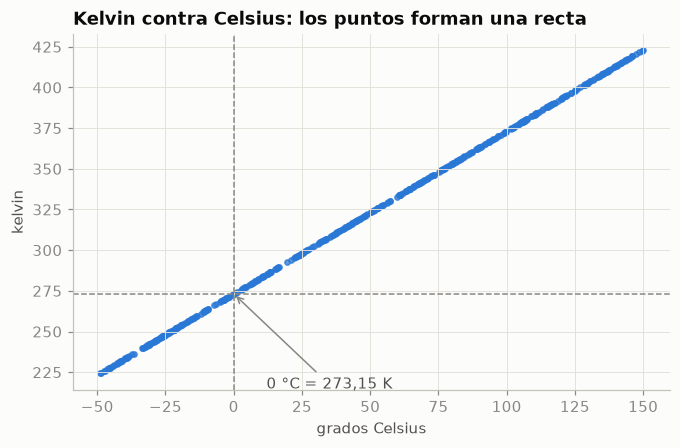

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.scatter(tem.celsius, tem.kelvin, s=12, color=AZUL, alpha=.75)
ax.axhline(273.15, color=GRIS, lw=1, ls='--'); ax.axvline(0, color=GRIS, lw=1, ls='--')
ax.annotate('0 °C = 273,15 K', (0, 273.15), (12, 215), color=TINTA2, arrowprops=dict(arrowstyle='->', color=GRIS))
ax.set(xlabel='grados Celsius', ylabel='kelvin', title='Kelvin contra Celsius: los puntos forman una recta')
plt.show()

Los puntos caen sobre una recta sin ninguna dispersión: la relación es exacta y lineal. Cuando la temperatura es 0 °C, el valor en kelvin es 273,15 (líneas punteadas). Eso es justo lo que puede representar una neurona sin activación, que también dibuja una recta: **w** es la pendiente y **b** el punto de corte.

## 2. Partición en entrenamiento y prueba

In [5]:
x, y = tem['celsius'].to_numpy(), tem['kelvin'].to_numpy()
xtr, xte, ytr, yte = train_test_split(x, y, test_size=0.2, random_state=SEMILLA)
print(f'entrenamiento: {len(xtr)} mediciones · prueba: {len(xte)} mediciones')

entrenamiento: 400 mediciones · prueba: 100 mediciones


La neurona aprende con 400 mediciones (80 %) y se mide con las otras 100 (20 %), que nunca ve al entrenar.

## 3. La neurona y su error

La neurona calcula **ŷ = w·x + b**. Para saber qué tan mal lo hace se usa el **error cuadrático medio** (ECM): el promedio de los errores al cuadrado,

$$\text{ECM} = \frac{1}{n}\sum (\hat y_i - y_i)^2 .$$

Aprender es mover w y b en la dirección en que baja el ECM. Esa dirección la dan las derivadas (los **gradientes**):

$$\frac{\partial\,\text{ECM}}{\partial w} = \frac{2}{n}\sum (\hat y_i - y_i)\,x_i \qquad \frac{\partial\,\text{ECM}}{\partial b} = \frac{2}{n}\sum (\hat y_i - y_i)$$

En cada **época** (una pasada por los datos), w y b se mueven un poco contra el gradiente: `w ← w − tasa · gradiente`. La **tasa de aprendizaje** dice qué tan grande es ese paso.

In [6]:
def neurona(x, w, b):
    return w * x + b

def ecm_y_gradientes(x, y, w, b):
    e = neurona(x, w, b) - y
    return np.mean(e ** 2), 2 * np.mean(e * x), 2 * np.mean(e)

def descenso(x, y, tasa, epocas, w=0.0, b=0.0):
    '''Descenso de gradiente: devuelve w, b y la historia (ECM, w, b) de cada época'''
    hist = []
    for _ in range(epocas):
        ecm, gw, gb = ecm_y_gradientes(x, y, w, b)
        hist.append((ecm, w, b))
        w, b = w - tasa * gw, b - tasa * gb
    return w, b, np.array(hist)

def adam(x, y, tasa, epocas, w=0.0, b=0.0, b1=0.9, b2=0.999, eps=1e-8):
    '''Adam: el mismo gradiente, pero con un paso que se adapta a cada parámetro (es el de la clase)'''
    mw = vw = mb = vb = 0.0
    hist = []
    for t in range(1, epocas + 1):
        ecm, gw, gb = ecm_y_gradientes(x, y, w, b)
        hist.append((ecm, w, b))
        mw, vw = b1 * mw + (1 - b1) * gw, b2 * vw + (1 - b2) * gw ** 2
        mb, vb = b1 * mb + (1 - b1) * gb, b2 * vb + (1 - b2) * gb ** 2
        w -= tasa * (mw / (1 - b1 ** t)) / (np.sqrt(vw / (1 - b2 ** t)) + eps)
        b -= tasa * (mb / (1 - b1 ** t)) / (np.sqrt(vb / (1 - b2 ** t)) + eps)
    return w, b, np.array(hist)

ecm0, gw0, gb0 = ecm_y_gradientes(xtr, ytr, 0.0, 0.0)
print(f'Con w = 0 y b = 0 la neurona dice siempre 0 K: ECM = {ecm0:,.0f}; gradiente de w = {gw0:,.0f}; gradiente de b = {gb0:,.0f}')

Con w = 0 y b = 0 la neurona dice siempre 0 K: ECM = 107,257; gradiente de w = -38,281; gradiente de b = -645


Antes de aprender, con w = 0 y b = 0, la neurona responde 0 K para todo y su ECM es 107.257. Los dos gradientes son negativos (w: −38.281; b: −645): hay que **subir** w y b. El de w es mucho más grande porque se multiplica por x, que llega a 150. Esa diferencia de escala es lo que complica el entrenamiento, como se ve a continuación.

## 4. Entrenar la neurona

### 4.1 Sin escalar la entrada, con descenso de gradiente simple

In [7]:
EPOCAS = 2000
w1, b1, h1 = descenso(xtr, ytr, tasa=1e-4, epocas=EPOCAS)
print(f'Después de {EPOCAS} épocas: w = {w1:.4f}, b = {b1:.2f} (los reales son 1 y 273,15) · ECM = {h1[-1, 0]:,.2f}')

Después de 2000 épocas: w = 2.9108, b = 55.38 (los reales son 1 y 273,15) · ECM = 26,857.79


Con la entrada sin escalar, la tasa tiene que ser pequeña (0,0001); con una mayor, el entrenamiento se desboca por culpa de los valores grandes de x. Después de 2000 épocas, w vale 2,9108, pero b apenas va en 55,38 de los 273,15 que necesita. La neurona compensa el sesgo corto con un peso demasiado grande, y el ECM sigue en 26.857,79. Aprende, pero muy despacio.

### 4.2 Escalando la entrada

Se divide la temperatura entre 100, de modo que x quede entre −0,5 y 1,5. Así los dos gradientes tienen tamaños parecidos y se puede usar un paso mucho mayor. Al final, el peso aprendido se vuelve a dividir entre 100 para llevarlo a grados.

In [8]:
ESC = 100
w2s, b2, h2 = descenso(xtr / ESC, ytr, tasa=0.1, epocas=EPOCAS)
w2 = w2s / ESC
print(f'Después de {EPOCAS} épocas: w = {w2:.4f}, b = {b2:.4f} · ECM = {h2[-1, 0]:.6f}')

Después de 2000 épocas: w = 1.0000, b = 273.1500 · ECM = 0.000000


Con la entrada escalada y una tasa de 0,1, en las mismas 2000 épocas la neurona llega a w = 1,0000 y b = 273,1500: es prácticamente la fórmula real. El ECM baja a 0,000000. **Escalar las entradas es una de las primeras cosas que se hacen antes de entrenar una red.**

### 4.3 Con Adam y sin escalar

Adam, el optimizador que usó la clase, ajusta el tamaño del paso de cada parámetro por separado. Por eso no le afecta tanto que w y b tengan escalas tan distintas.

In [9]:
w3, b3, h3 = adam(xtr, ytr, tasa=1.0, epocas=EPOCAS)
print(f'Después de {EPOCAS} épocas: w = {w3:.4f}, b = {b3:.4f} · ECM = {h3[-1, 0]:.6f}')

Después de 2000 épocas: w = 1.0000, b = 273.1500 · ECM = 0.000000


Con Adam y una tasa de 1, sin escalar nada, la neurona termina en w = 1,0000 y b = 273,1500 (ECM = 0,000000). Es el mismo resultado al que llegó con la entrada escalada.

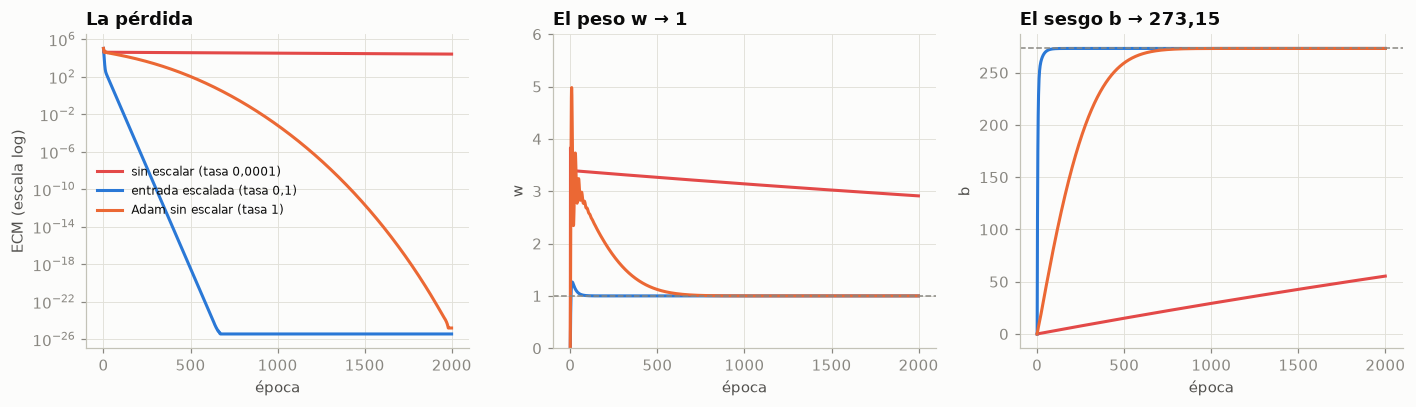

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
for h, nom, col in [(h1, 'sin escalar (tasa 0,0001)', ROJO), (h2, 'entrada escalada (tasa 0,1)', AZUL), (h3, 'Adam sin escalar (tasa 1)', NARANJA)]:
    axs[0].plot(h[:, 0], color=col, label=nom)
    axs[1].plot(h[:, 1] if h is not h2 else h[:, 1] / ESC, color=col)
    axs[2].plot(h[:, 2], color=col)
axs[0].set(yscale='log', xlabel='época', ylabel='ECM (escala log)', title='La pérdida')
axs[1].axhline(1, color=GRIS, ls='--', lw=1); axs[1].set(xlabel='época', ylabel='w', title='El peso w → 1', ylim=(0, 6))
axs[2].axhline(273.15, color=GRIS, ls='--', lw=1); axs[2].set(xlabel='época', ylabel='b', title='El sesgo b → 273,15')
axs[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

La gráfica de la izquierda está en escala logarítmica: cada marca es diez veces menos error. Con la entrada escalada (azul) y con Adam (naranja), la pérdida cae muchos órdenes de magnitud. Sin escalar (rojo), se estanca. En el centro y a la derecha se ve la causa: sin escalar, **b** sube muy despacio hacia 273,15 y **w** se pasa de 1 para compensar. En los otros dos casos, los dos parámetros llegan a sus valores reales (líneas punteadas).

## 5. Resultados y métricas en la prueba

In [11]:
def metricas(w, b, x, y):
    p = neurona(x, w, b)
    return {'MAE': mean_absolute_error(y, p), 'RMSE': mean_squared_error(y, p) ** 0.5, 'R²': r2_score(y, p)}

filas = []
for nom, w, b in [('Sin escalar (GD)', w1, b1), ('Entrada escalada (GD)', w2, b2), ('Adam sin escalar', w3, b3)]:
    for parte, xx, yy in [('entrenamiento', xtr, ytr), ('prueba', xte, yte)]:
        filas.append({'modelo': nom, 'datos': parte, 'w': w, 'b': b, **metricas(w, b, xx, yy)})
res = pd.DataFrame(filas).set_index(['modelo', 'datos'])
res.style.format({'w': '{:.4f}', 'b': '{:.4f}', 'MAE': '{:.4f}', 'RMSE': '{:.4f}', 'R²': '{:.6f}'})

El **MAE** (error absoluto medio) dice en cuántos kelvin se equivoca la neurona, en promedio; el **RMSE** castiga más los errores grandes, y el **R²** compara contra predecir siempre el promedio. El modelo sin escalar se equivoca en 136,5 K en la prueba y su R² es −7,02: negativo, es decir, **peor que decir siempre la temperatura promedio**. Las 2.000 épocas no le alcanzaron. Con la entrada escalada y con Adam, el MAE de prueba es 0,0000 K y el R² es 1: los datos no tienen ruido y la recta los reproduce exactamente. Entrenamiento y prueba dan casi lo mismo en los tres: no hay sobreajuste, como es de esperar con solo dos parámetros.

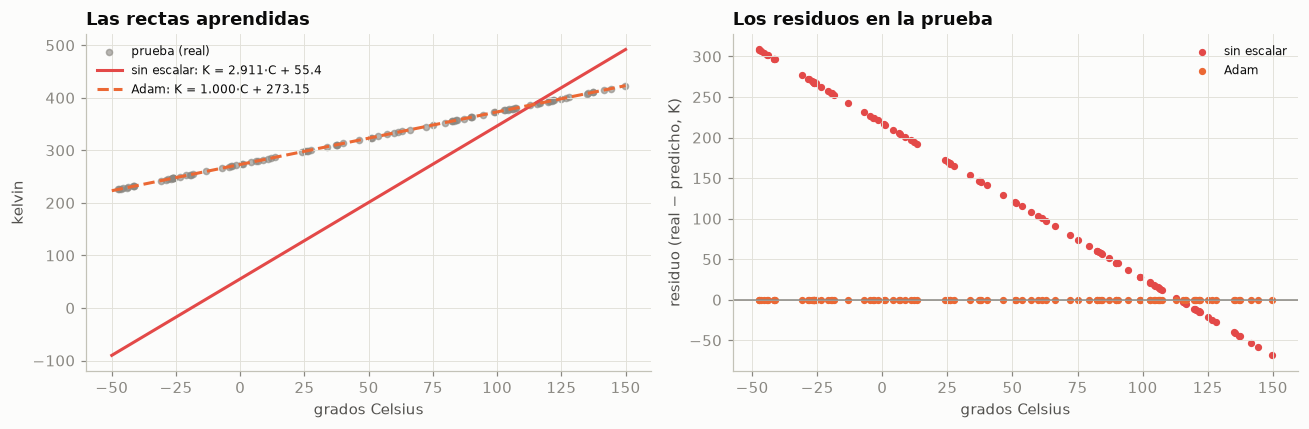

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
xs = np.linspace(-50, 150, 50)
axs[0].scatter(xte, yte, s=16, color=GRIS, alpha=.6, label='prueba (real)')
axs[0].plot(xs, neurona(xs, w1, b1), color=ROJO, label=f'sin escalar: K = {w1:.3f}·C + {b1:.1f}')
axs[0].plot(xs, neurona(xs, w3, b3), color=NARANJA, ls='--', label=f'Adam: K = {w3:.3f}·C + {b3:.2f}')
axs[0].set(xlabel='grados Celsius', ylabel='kelvin', title='Las rectas aprendidas'); axs[0].legend(fontsize=8)
axs[1].scatter(xte, yte - neurona(xte, w1, b1), s=14, color=ROJO, label='sin escalar')
axs[1].scatter(xte, yte - neurona(xte, w3, b3), s=14, color=NARANJA, label='Adam')
axs[1].axhline(0, color=GRIS, lw=1)
axs[1].set(xlabel='grados Celsius', ylabel='residuo (real − predicho, K)', title='Los residuos en la prueba'); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

A la izquierda, la recta de Adam pasa exactamente por los puntos de prueba. La de «sin escalar» queda lejos: demasiado inclinada y muy por debajo en las temperaturas bajas. A la derecha están los residuos: en el modelo sin escalar forman una recta, un **patrón** que delata que al modelo le falta aprender (el sesgo quedó corto). En el de Adam son prácticamente cero. Unos residuos con forma son la señal de un modelo incompleto.

## 6. La tasa de aprendizaje

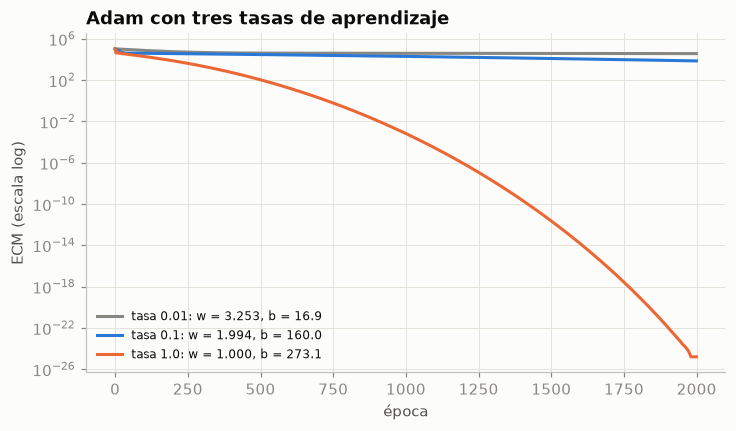

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 4))
TASAS = [0.01, 0.1, 1.0]
final = {}
for tasa, col in zip(TASAS, [GRIS, AZUL, NARANJA]):
    w, b, h = adam(xtr, ytr, tasa=tasa, epocas=EPOCAS)
    final[tasa] = (w, b, h[-1, 0])
    ax.plot(h[:, 0], color=col, label=f'tasa {tasa}: w = {w:.3f}, b = {b:.1f}')
ax.set(yscale='log', xlabel='época', ylabel='ECM (escala log)', title='Adam con tres tasas de aprendizaje'); ax.legend(fontsize=8)
plt.show()

La tasa de aprendizaje decide la velocidad. Con 0,01, Adam mueve cada parámetro unas centésimas por época: después de 2000 épocas, b apenas llega a 16,9. Con 0,1 llega a 160,0, y con 1, a 273,15, el valor real. Una tasa demasiado pequeña desperdicia épocas; una demasiado grande puede hacer que el error oscile. Elegirla es parte del oficio.

## 7. Comparación con la regresión lineal

In [14]:
lr = LinearRegression().fit(xtr.reshape(-1, 1), ytr)
print(f'Regresión lineal (mínimos cuadrados): w = {lr.coef_[0]:.6f}, b = {lr.intercept_:.6f}')
print(f'Neurona con Adam:                     w = {w3:.6f}, b = {b3:.6f}')

Regresión lineal (mínimos cuadrados): w = 1.000000, b = 273.150000
Neurona con Adam:                     w = 1.000000, b = 273.150000


La regresión lineal encuentra la solución exacta de una vez, con una fórmula: w = 1,000000 y b = 273,150000. La neurona llega al mismo lugar por aproximaciones sucesivas. **Una neurona sin activación es una regresión lineal entrenada paso a paso.** La ventaja de entrenar así aparece cuando se juntan muchas neuronas con activaciones no lineales: para esas redes no hay fórmula cerrada y el descenso de gradiente es la única vía. Eso es lo que hace la práctica de las fincas cafeteras.

## Conclusiones

1. Una sola neurona (ŷ = w·x + b) **descubre la fórmula kelvin = 1 × celsius + 273,15** a partir de los datos: con Adam llega a w = 1,0000 y b = 273,1500, con un error de prueba de 0,0000 K (los datos no tienen ruido).
2. Aprender es bajar el error moviendo w y b contra el gradiente, época por época.
3. **La escala importa**: sin escalar la entrada, el descenso de gradiente simple deja b en 55,4 después de 2000 épocas. Escalando, o con Adam, converge.
4. La tasa de aprendizaje controla la velocidad: muy pequeña, el aprendizaje es lento; adecuada, converge en pocas épocas.
5. Con una relación lineal, la neurona y la regresión lineal dan lo mismo. Las redes se justifican cuando la relación no es lineal.

## Retos

1. Cambie la tasa del descenso simple sin escalar a 0,001. ¿Qué pasa con el ECM? ¿Por qué?
2. Agregue ruido a los datos (por ejemplo, `y + np.random.normal(0, 0.5, len(y))`, como un termómetro impreciso) y entrene otra vez. ¿Cuánto cambian w, b y el MAE?
3. Entrene la neurona al revés, para pasar de kelvin a Celsius. ¿Qué valores de w y b espera?
4. Repita el ejercicio con Celsius → Fahrenheit (F = 1,8·C + 32), como en la clase.
5. Si tiene Keras, entrene `Dense(1)` con Adam y compare los pesos que encuentra con los de este cuaderno.